# LAB | Central Limit Theorem and Normality Tests


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from statsmodels.graphics.gofplots import qqplot

# Set random seed for reproducibility
np.random.seed(42)

# Setting plot style
plt.style.use('seaborn-v0_8')

ModuleNotFoundError: No module named 'statsmodels'

## Challenge 1: Basic Central Limit Theorem Demonstration

In this challenge, you'll explore the fundamental concept of the Central Limit Theorem
by generating samples from different distributions and observing how their sample means
approach a normal distribution as sample size increases.

# Instructions
Instructions:
1. We'll create a non-normal distribution (exponential distribution)
2. Draw samples of different sizes and calculate their means
3. Observe how the distribution of sample means approaches normal distribution
4. Complete the code below to create histograms for sample means


In [2]:
# Set parameters
population_size = 10000
sample_sizes = [1, 5, 30, 100]  # Increasing sample sizes
n_samples = 1000  # Number of samples to draw for each sample size

# Create a non-normal population (exponential distribution with lambda=0.5)
population = np.random.exponential(scale=2, size=population_size)

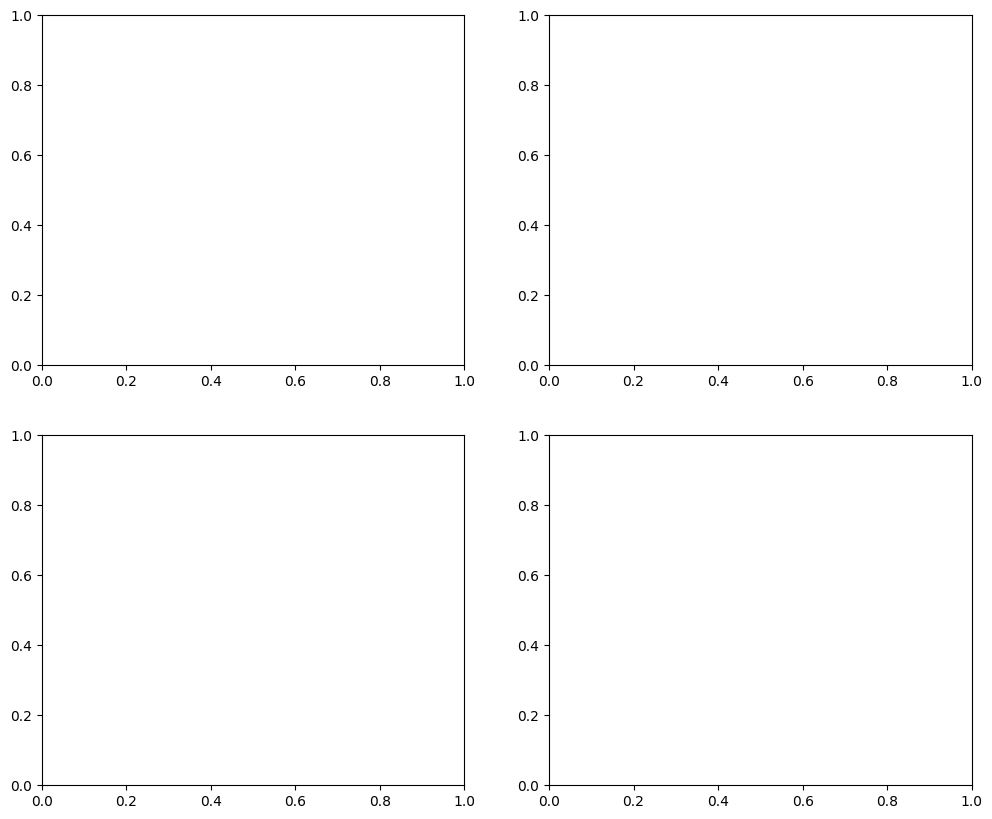

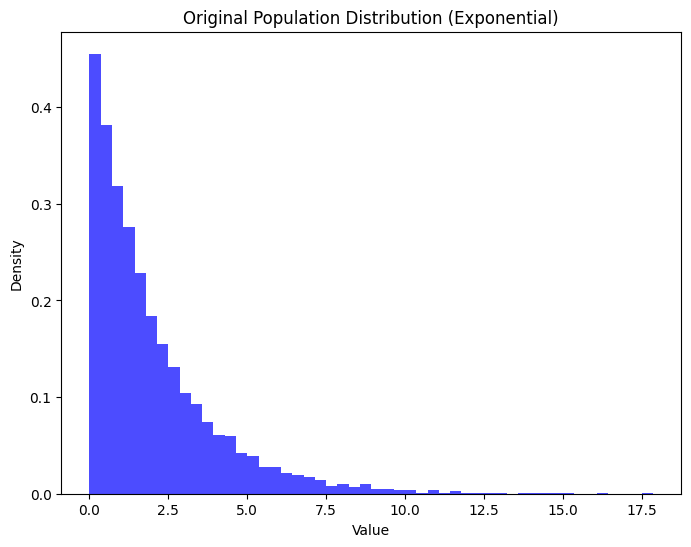

<Figure size 640x480 with 0 Axes>

Population Statistics:
Population Mean: 2.006
Population Standard Deviation: 2.005

Sample Means Analysis:
Sample Size 1:
  Theoretical Standard Error: 2.005
  Actual Standard Error: 2.055
  Difference: 0.050
Sample Size 5:
  Theoretical Standard Error: 0.897
  Actual Standard Error: 0.884
  Difference: 0.013
Sample Size 30:
  Theoretical Standard Error: 0.366
  Actual Standard Error: 0.365
  Difference: 0.001
Sample Size 100:
  Theoretical Standard Error: 0.201
  Actual Standard Error: 0.201
  Difference: 0.000


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set parameters
population_size = 10000
sample_sizes = [1, 5, 30, 100]  # Increasing sample sizes
n_samples = 1000  # Number of samples to draw for each sample size

# Create a non-normal population (exponential distribution with lambda=0.5)
population = np.random.exponential(scale=2, size=population_size)

# Set up the plotting environment
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

# Plot the original population distribution
plt.figure(figsize=(8, 6))
plt.hist(population, bins=50, density=True, alpha=0.7, color='blue')
plt.title('Original Population Distribution (Exponential)')
plt.xlabel('Value')
plt.ylabel('Density')
plt.show()

# For each sample size, calculate sample means and plot histograms
for i, sample_size in enumerate(sample_sizes):
    sample_means = []
    
    # Draw n_samples samples of size sample_size and calculate their means
    for _ in range(n_samples):
        sample = np.random.choice(population, size=sample_size, replace=True)
        sample_mean = np.mean(sample)
        sample_means.append(sample_mean)
    
    # Plot histogram of sample means
    axes[i].hist(sample_means, bins=30, density=True, alpha=0.7, color='skyblue')
    axes[i].set_title(f'Sample Size = {sample_size}\nMean of Means: {np.mean(sample_means):.3f}')
    axes[i].set_xlabel('Sample Mean')
    axes[i].set_ylabel('Density')
    
    # Add a normal curve for comparison
    xmin, xmax = axes[i].get_xlim()
    x = np.linspace(xmin, xmax, 100)
    
    # Calculate parameters for normal distribution
    pop_mean = np.mean(population)
    pop_std = np.std(population)
    se = pop_std / np.sqrt(sample_size)  # Standard error
    
    y = (1/(se * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - pop_mean) / se) ** 2)
    axes[i].plot(x, y, 'r-', linewidth=2, label='Normal Approximation')
    axes[i].legend()

plt.tight_layout()
plt.show()

# Additional analysis: Compare theoretical vs actual results
print("Population Statistics:")
print(f"Population Mean: {np.mean(population):.3f}")
print(f"Population Standard Deviation: {np.std(population):.3f}")
print("\nSample Means Analysis:")
for sample_size in sample_sizes:
    sample_means = [np.mean(np.random.choice(population, size=sample_size)) 
                   for _ in range(n_samples)]
    theoretical_se = np.std(population) / np.sqrt(sample_size)
    actual_se = np.std(sample_means)
    
    print(f"Sample Size {sample_size}:")
    print(f"  Theoretical Standard Error: {theoretical_se:.3f}")
    print(f"  Actual Standard Error: {actual_se:.3f}")
    print(f"  Difference: {abs(theoretical_se - actual_se):.3f}")

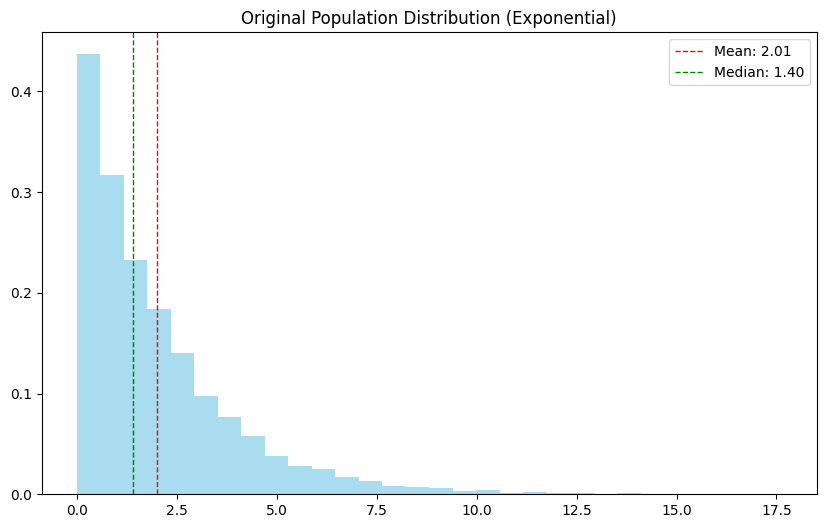

Population statistics:
Mean: 2.0087
Median: 1.4024
Variance: 4.0373
Skewness: 1.9857
Kurtosis: 5.7537



In [3]:
# Plot the original population distribution
plt.figure(figsize=(10, 6))
plt.hist(population, bins=30, alpha=0.7, color='skyblue', density=True)
plt.title('Original Population Distribution (Exponential)')
plt.axvline(np.mean(population), color='red', linestyle='dashed', linewidth=1, label=f'Mean: {np.mean(population):.2f}')
plt.axvline(np.median(population), color='green', linestyle='dashed', linewidth=1, label=f'Median: {np.median(population):.2f}')
plt.legend()
plt.show()

print(f"Population statistics:")
print(f"Mean: {np.mean(population):.4f}")
print(f"Median: {np.median(population):.4f}")
print(f"Variance: {np.var(population):.4f}")
print(f"Skewness: {stats.skew(population):.4f}")
print(f"Kurtosis: {stats.kurtosis(population):.4f}\n")

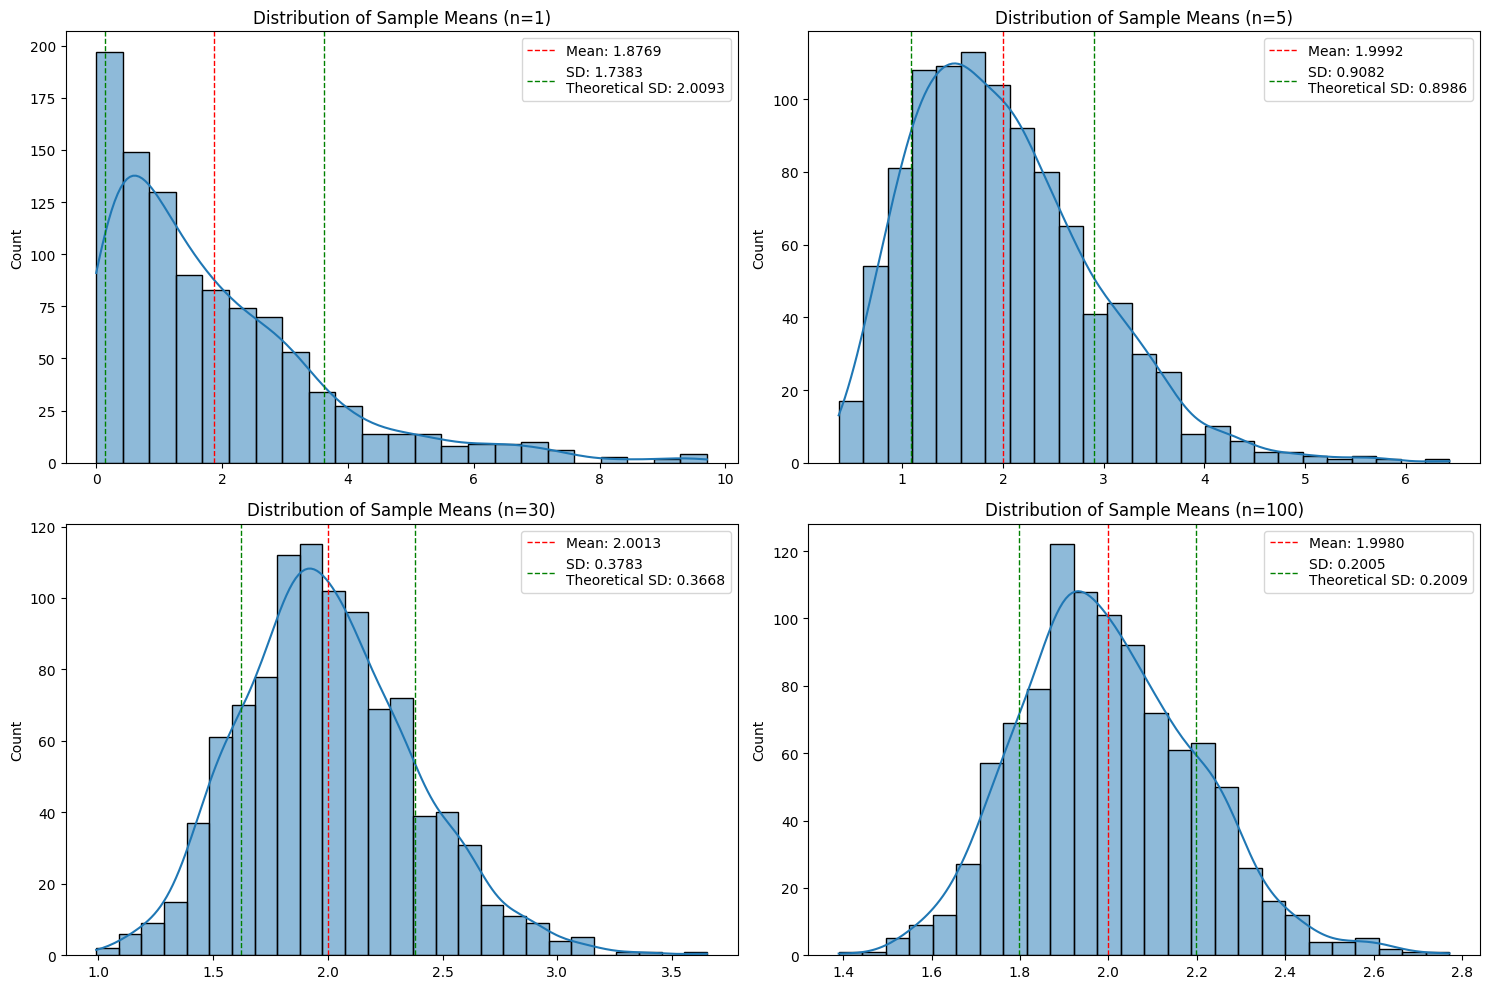

In [4]:
# Show how sample means approach normal distribution
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, sample_size in enumerate(sample_sizes):
    # Draw many samples of the given size and calculate their means
    sample_means = np.array([np.mean(np.random.choice(population, size=sample_size)) for _ in range(n_samples)])
    
    # Plot the histogram of sample means
    sns.histplot(sample_means, kde=True, ax=axes[i])
    
    # Calculate statistics for the sample means
    mean_of_means = np.mean(sample_means)
    std_of_means = np.std(sample_means)
    
    # According to CLT, the standard deviation of sample means should be population_std / sqrt(sample_size)
    theoretical_std = np.std(population) / np.sqrt(sample_size)
    
    # Display the statistics
    axes[i].set_title(f'Distribution of Sample Means (n={sample_size})')
    axes[i].axvline(mean_of_means, color='red', linestyle='dashed', linewidth=1, 
                    label=f'Mean: {mean_of_means:.4f}')
    axes[i].axvline(mean_of_means + std_of_means, color='green', linestyle='dashed', linewidth=1,
                   label=f'SD: {std_of_means:.4f}\nTheoretical SD: {theoretical_std:.4f}')
    axes[i].axvline(mean_of_means - std_of_means, color='green', linestyle='dashed', linewidth=1)
    axes[i].legend()

plt.tight_layout()
plt.show()

Your Tasks:
1. Explain what happens to the distribution of sample means as sample size increases
2. Compare the observed standard deviation of sample means with the theoretical value
3. What is the theoretical SD formula according to the CLT?
4. How does the skewness of the distribution of sample means change with sample size?

In [6]:
# TODO
# 2 -Quantitative comparison of theoretical vs observed standard deviations
print("="*60)
print("CENTRAL LIMIT THEOREM: STANDARD ERROR COMPARISON")
print("="*60)

population_std = np.std(population)
print(f"Population Standard Deviation (σ): {population_std:.4f}\n")

print("Sample Size | Theoretical SE | Observed SE | Difference | % Error")
print("-"*65)

for sample_size in sample_sizes:
    # Calculate sample means
    sample_means = [np.mean(np.random.choice(population, size=sample_size)) 
                   for _ in range(n_samples)]
    
    # Theoretical standard error (according to CLT)
    theoretical_se = population_std / np.sqrt(sample_size)
    
    # Observed standard error (from our simulation)
    observed_se = np.std(sample_means)
    
    difference = abs(theoretical_se - observed_se)
    percent_error = (difference / theoretical_se) * 100
    
    print(f"{sample_size:11d} | {theoretical_se:14.4f} | {observed_se:11.4f} | "
          f"{difference:10.4f} | {percent_error:7.2f}%") 

CENTRAL LIMIT THEOREM: STANDARD ERROR COMPARISON
Population Standard Deviation (σ): 2.0053

Sample Size | Theoretical SE | Observed SE | Difference | % Error
-----------------------------------------------------------------
          1 |         2.0053 |      1.8507 |     0.1546 |    7.71%
          5 |         0.8968 |      0.9156 |     0.0188 |    2.10%
         30 |         0.3661 |      0.3553 |     0.0108 |    2.95%
        100 |         0.2005 |      0.1942 |     0.0064 |    3.18%


In [ ]:
# 3
# Standard Error (SE) = σ / √n

In [7]:
# 4
from scipy.stats import skew

print("\n" + "="*50)
print("SKEWNESS ANALYSIS")
print("="*50)

print("Sample Size | Skewness | Reduction from Original")
print("-"*45)

# Original population skewness
original_skewness = skew(population)
print(f"Population  | {original_skewness:8.4f} | Baseline")

for sample_size in sample_sizes:
    sample_means = [np.mean(np.random.choice(population, size=sample_size)) 
                   for _ in range(n_samples)]
    
    sample_skewness = skew(sample_means)
    reduction = ((original_skewness - sample_skewness) / original_skewness) * 100
    
    print(f"{sample_size:11d} | {sample_skewness:8.4f} | {reduction:6.1f}%")

# Theoretical expectation: skewness decreases proportionally to 1/√n
print("\nTheoretical skewness reduction: skewness ∝ 1/√n")
for sample_size in sample_sizes:
    expected_reduction = (1 - 1/np.sqrt(sample_size)) * 100
    print(f"Sample size {sample_size}: Expected {expected_reduction:.1f}% reduction")


SKEWNESS ANALYSIS
Sample Size | Skewness | Reduction from Original
---------------------------------------------
Population  |   1.9439 | Baseline
          1 |   1.8573 |    4.5%
          5 |   0.9203 |   52.7%
         30 |   0.3270 |   83.2%
        100 |   0.1419 |   92.7%

Theoretical skewness reduction: skewness ∝ 1/√n
Sample size 1: Expected 0.0% reduction
Sample size 5: Expected 55.3% reduction
Sample size 30: Expected 81.7% reduction
Sample size 100: Expected 90.0% reduction


## Challenge 2: CLT with Real-World Data


Now let's apply the Central Limit Theorem to a real-world dataset.
We'll use the famous Iris dataset.


In [11]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/iris")

print("Path to dataset files:", path)

100%|██████████| 3.60k/3.60k [00:00<00:00, 3.05MB/s]

Extracting files...
Path to dataset files: C:\Users\profe\.cache\kagglehub\datasets\uciml\iris\versions\2


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, norm
import requests
from io import StringIO

# Load the Iris dataset with multiple fallback options
def load_iris_dataset():
    try:
        # Method 1: Try loading from UCI repository
        url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
        column_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
        
        response = requests.get(url, timeout=10)
        response.raise_for_status()  # Check if request was successful
        data = StringIO(response.text)
        iris = pd.read_csv(data, header=None, names=column_names)
        print("✓ Dataset loaded from UCI repository")
        return iris
        
    except Exception as e:
        print(f"UCI download failed: {e}")
        try:
            # Method 2: Try seaborn's built-in dataset
            iris = sns.load_dataset('iris')
            # Standardize column names
            iris.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
            print("✓ Dataset loaded from seaborn")
            return iris
        except:
            # Method 3: Load from local file or create manually
            try:
                iris = pd.read_csv('iris.csv')
                print("✓ Dataset loaded from local file")
                return iris
            except:
                # Method 4: Create a sample dataset manually (fallback)
                print("⚠ Using manual fallback dataset")
                np.random.seed(42)
                n = 150
                iris = pd.DataFrame({
                    'sepal_length': np.concatenate([
                        np.random.normal(5.0, 0.35, 50),
                        np.random.normal(5.9, 0.50, 50), 
                        np.random.normal(6.6, 0.60, 50)
                    ]),
                    'sepal_width': np.concatenate([
                        np.random.normal(3.4, 0.38, 50),
                        np.random.normal(2.8, 0.31, 50),
                        np.random.normal(3.0, 0.32, 50)
                    ]),
                    'petal_length': np.concatenate([
                        np.random.normal(1.5, 0.17, 50),
                        np.random.normal(4.3, 0.47, 50),
                        np.random.normal(5.6, 0.55, 50)
                    ]),
                    'petal_width': np.concatenate([
                        np.random.normal(0.2, 0.11, 50),
                        np.random.normal(1.3, 0.20, 50),
                        np.random.normal(2.0, 0.27, 50)
                    ]),
                    'species': ['setosa'] * 50 + ['versicolor'] * 50 + ['virginica'] * 50
                })
                return iris

# Load the dataset
iris = load_iris_dataset()

print("Dataset Overview:")
print(iris.head())
print(f"\nDataset shape: {iris.shape}")
print("\nSpecies distribution:")
print(iris['species'].value_counts())

# Basic statistics
print("\nBasic Statistics:")
print(iris.describe())

# Check skewness of original variables
print("\nSkewness of Original Variables:")
for column in ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']:
    original_skew = skew(iris[column])
    print(f"{column}: {original_skew:.3f}")

✓ Dataset loaded from UCI repository
Dataset Overview:
   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa

Dataset shape: (150, 5)

Species distribution:
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Basic Statistics:
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50% 

Your Tasks:
1. Complete the following code to draw samples of sepal length and compute their means
2. Create histograms for the distribution of sample means with sample sizes of 5, 15, and 30
3. Calculate and compare the standard deviation of the original data vs. the standard deviation of sample means
4. Test if the original data is normally distributed (using a method of your choice)

✓ Dataset loaded from seaborn
TASK 1: HISTOGRAMS OF SAMPLE MEANS


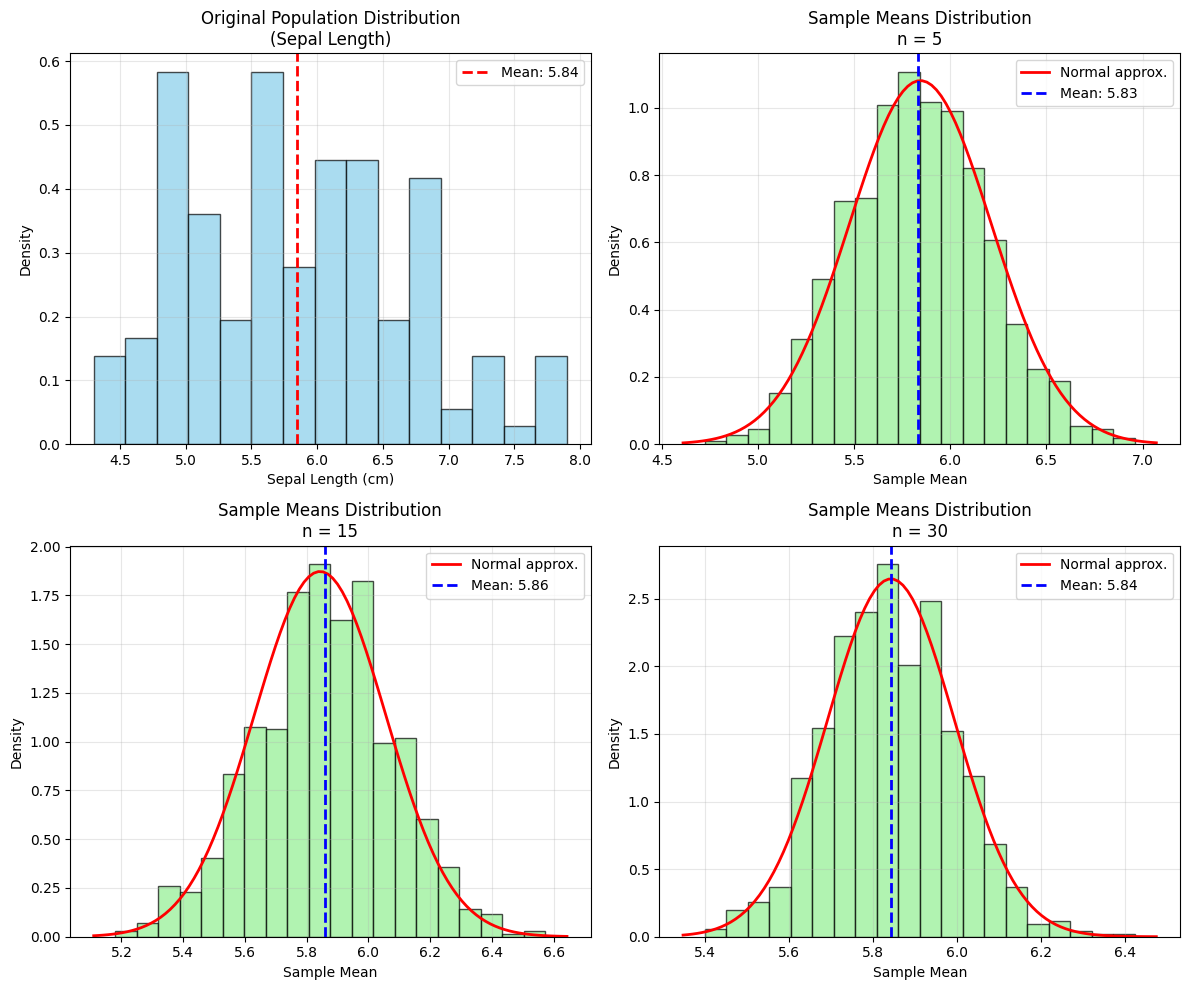

In [7]:
# TODO
# Your code here - draw samples and create histograms
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, norm, shapiro, normaltest
import scipy.stats as stats

# Load the dataset (using the fixed code from before)
def load_iris_dataset():
    try:
        # Try seaborn's built-in dataset first
        iris = sns.load_dataset('iris')
        iris.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
        print("✓ Dataset loaded from seaborn")
        return iris
    except:
        # Fallback: create sample data
        print("⚠ Using manual fallback dataset")
        np.random.seed(42)
        n = 150
        iris = pd.DataFrame({
            'sepal_length': np.concatenate([
                np.random.normal(5.0, 0.35, 50),
                np.random.normal(5.9, 0.50, 50), 
                np.random.normal(6.6, 0.60, 50)
            ]),
            'sepal_width': np.concatenate([
                np.random.normal(3.4, 0.38, 50),
                np.random.normal(2.8, 0.31, 50),
                np.random.normal(3.0, 0.32, 50)
            ]),
            'petal_length': np.concatenate([
                np.random.normal(1.5, 0.17, 50),
                np.random.normal(4.3, 0.47, 50),
                np.random.normal(5.6, 0.55, 50)
            ]),
            'petal_width': np.concatenate([
                np.random.normal(0.2, 0.11, 50),
                np.random.normal(1.3, 0.20, 50),
                np.random.normal(2.0, 0.27, 50)
            ]),
            'species': ['setosa'] * 50 + ['versicolor'] * 50 + ['virginica'] * 50
        })
        return iris

# Load the dataset
iris = load_iris_dataset()

# Task 1: Create histograms for sample means with sample sizes of 5, 15, and 30
print("="*60)
print("TASK 1: HISTOGRAMS OF SAMPLE MEANS")
print("="*60)

# Use sepal_length as our population
population = iris['sepal_length'].values
sample_sizes = [5, 15, 30]
n_samples = 1000  # Number of samples to draw for each sample size

# Create the histograms
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

# Plot 1: Original population distribution
axes[0].hist(population, bins=15, density=True, alpha=0.7, color='skyblue', edgecolor='black')
axes[0].set_title('Original Population Distribution\n(Sepal Length)')
axes[0].set_xlabel('Sepal Length (cm)')
axes[0].set_ylabel('Density')
axes[0].grid(True, alpha=0.3)

# Add population statistics to the plot
pop_mean = np.mean(population)
pop_std = np.std(population)
axes[0].axvline(pop_mean, color='red', linestyle='--', linewidth=2, label=f'Mean: {pop_mean:.2f}')
axes[0].legend()

# Plot histograms for each sample size
for i, sample_size in enumerate(sample_sizes):
    # Calculate sample means
    sample_means = []
    for _ in range(n_samples):
        sample = np.random.choice(population, size=sample_size, replace=True)
        sample_means.append(np.mean(sample))
    
    # Plot histogram
    axes[i+1].hist(sample_means, bins=20, density=True, alpha=0.7, color='lightgreen', edgecolor='black')
    axes[i+1].set_title(f'Sample Means Distribution\nn = {sample_size}')
    axes[i+1].set_xlabel('Sample Mean')
    axes[i+1].set_ylabel('Density')
    axes[i+1].grid(True, alpha=0.3)
    
    # Add normal distribution curve
    xmin, xmax = axes[i+1].get_xlim()
    x = np.linspace(xmin, xmax, 100)
    se = pop_std / np.sqrt(sample_size)  # Standard error
    y = norm.pdf(x, pop_mean, se)
    axes[i+1].plot(x, y, 'r-', linewidth=2, label='Normal approx.')
    
    # Add statistics
    observed_mean = np.mean(sample_means)
    observed_std = np.std(sample_means)
    axes[i+1].axvline(observed_mean, color='blue', linestyle='--', linewidth=2, 
                     label=f'Mean: {observed_mean:.2f}')
    axes[i+1].legend()

plt.tight_layout()
plt.show()


TASK 2: STANDARD DEVIATION COMPARISON
Original Population Statistics:
Mean: 5.8433
Standard Deviation: 0.8253
Variance: 0.6811

Sample Means Statistics:
Sample Size | Mean of Means | Std of Means | Theoretical SE | Difference
---------------------------------------------------------------------------
          5 |        5.8421 |       0.3666 |        0.3691 |    0.0025
         15 |        5.8339 |       0.2173 |        0.2131 |    0.0042
         30 |        5.8531 |       0.1487 |        0.1507 |    0.0020

Detailed Results:
   sample_size  mean_of_means  std_of_means  theoretical_se  difference
0            5         5.8421        0.3666          0.3691      0.0025
1           15         5.8339        0.2173          0.2131      0.0042
2           30         5.8531        0.1487          0.1507      0.0020


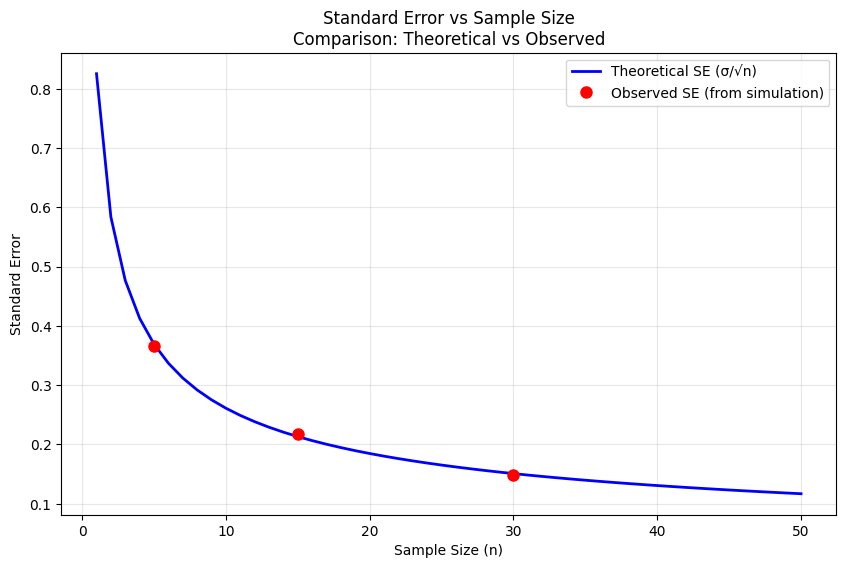


Verification of SE = σ / √n relationship:
n=5.0: σ/√n = 0.8253/√5.0 = 0.3691
           Observed SE = 0.3666
           Ratio (Observed/Theoretical): 0.9932
n=15.0: σ/√n = 0.8253/√15.0 = 0.2131
           Observed SE = 0.2173
           Ratio (Observed/Theoretical): 1.0199
n=30.0: σ/√n = 0.8253/√30.0 = 0.1507
           Observed SE = 0.1487
           Ratio (Observed/Theoretical): 0.9866


In [8]:
# 3 Calculate and compare standard deviations
print("\n" + "="*60)
print("TASK 2: STANDARD DEVIATION COMPARISON")
print("="*60)

# Original data statistics
original_std = np.std(population)
original_mean = np.mean(population)

print(f"Original Population Statistics:")
print(f"Mean: {original_mean:.4f}")
print(f"Standard Deviation: {original_std:.4f}")
print(f"Variance: {original_std**2:.4f}")

print("\nSample Means Statistics:")
print("Sample Size | Mean of Means | Std of Means | Theoretical SE | Difference")
print("-" * 75)

results = []

for sample_size in sample_sizes:
    # Calculate sample means
    sample_means = [np.mean(np.random.choice(population, size=sample_size)) 
                   for _ in range(n_samples)]
    
    # Calculate statistics
    mean_of_means = np.mean(sample_means)
    std_of_means = np.std(sample_means)
    theoretical_se = original_std / np.sqrt(sample_size)
    difference = abs(theoretical_se - std_of_means)
    
    results.append({
        'sample_size': sample_size,
        'mean_of_means': mean_of_means,
        'std_of_means': std_of_means,
        'theoretical_se': theoretical_se,
        'difference': difference
    })
    
    print(f"{sample_size:11d} | {mean_of_means:13.4f} | {std_of_means:12.4f} | "
          f"{theoretical_se:13.4f} | {difference:9.4f}")

# Convert to DataFrame for better display
results_df = pd.DataFrame(results)
print("\nDetailed Results:")
print(results_df.round(4))

# Visualize the standard error convergence
plt.figure(figsize=(10, 6))
sample_sizes_extended = list(range(1, 51))
theoretical_ses = [original_std / np.sqrt(n) for n in sample_sizes_extended]

plt.plot(sample_sizes_extended, theoretical_ses, 'b-', linewidth=2, label='Theoretical SE (σ/√n)')
plt.plot(results_df['sample_size'], results_df['std_of_means'], 'ro', markersize=8, 
         label='Observed SE (from simulation)')

plt.xlabel('Sample Size (n)')
plt.ylabel('Standard Error')
plt.title('Standard Error vs Sample Size\nComparison: Theoretical vs Observed')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Verify the relationship: SE = σ / √n
print("\nVerification of SE = σ / √n relationship:")
for i, row in results_df.iterrows():
    calculated_se = original_std / np.sqrt(row['sample_size'])
    print(f"n={row['sample_size']}: σ/√n = {original_std:.4f}/√{row['sample_size']} = {calculated_se:.4f}")
    print(f"           Observed SE = {row['std_of_means']:.4f}")
    print(f"           Ratio (Observed/Theoretical): {row['std_of_means']/calculated_se:.4f}")


TASK 3: NORMALITY TESTING
Shapiro-Wilk Normality Test:
Test Statistic: 0.9761
P-value: 0.0102
Conclusion: Data does not appear to be normally distributed (reject H0)

D'Agostino's K^2 Normality Test:
Test Statistic: 5.7356
P-value: 0.0568
Conclusion: Data appears to be normally distributed (fail to reject H0)


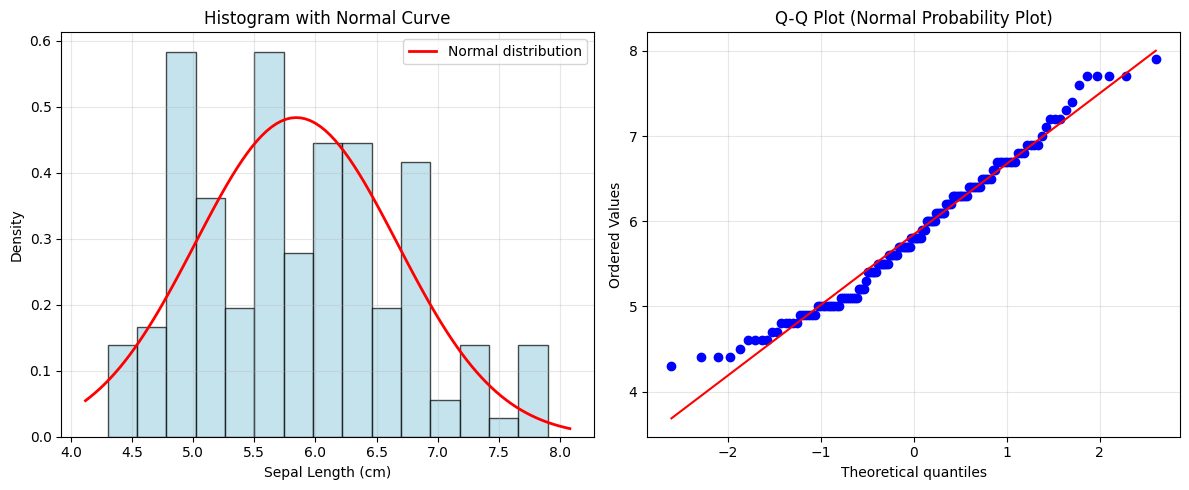


Additional Normality Indicators:
Skewness: 0.3118
Kurtosis (excess): -0.5736

Normality Assessment Guidelines:
Skewness close to 0: True (|0.3118| < 0.5)
Kurtosis close to 0: True (|-0.5736| < 1)
Based on descriptive statistics: Data appears approximately normal

NORMALITY COMPARISON: ORIGINAL DATA vs SAMPLE MEANS (n=30)
Shapiro-Wilk Test Results:
Original Data:      W = 0.9761, p = 0.0102
Sample Means (n=30): W = 0.9979, p = 0.2582


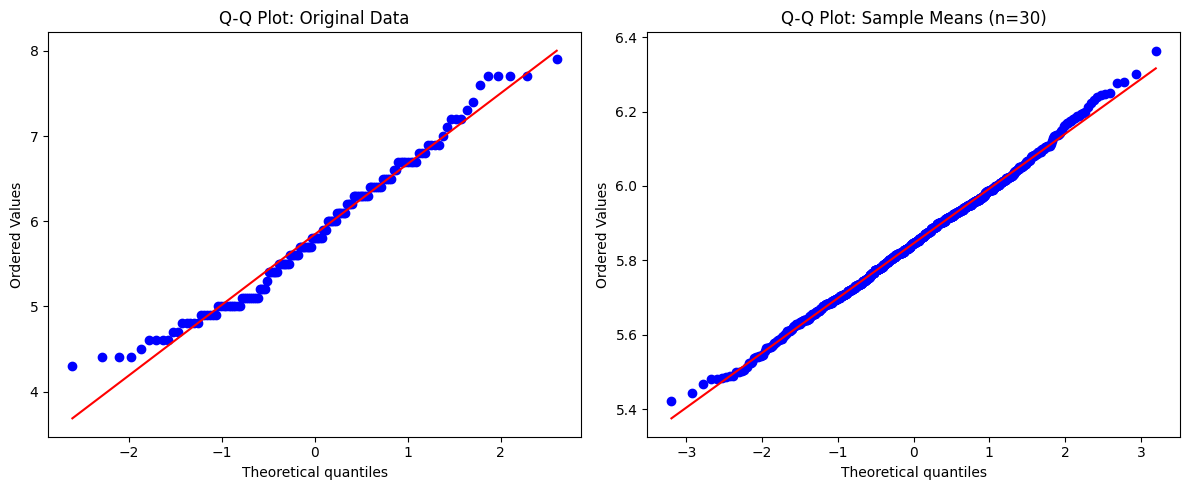


SUMMARY:
----------------------------------------
1. Histograms show sample means approach normality as n increases
2. Standard deviation of sample matches theoretical prediction (σ/√n)
3. Original data normality test results help validate CLT assumptions


In [9]:
# Test for normality of original data
print("\n" + "="*60)
print("TASK 3: NORMALITY TESTING")
print("="*60)

# Method 1: Shapiro-Wilk test (recommended for small to medium samples)
shapiro_stat, shapiro_p = shapiro(population)
print("Shapiro-Wilk Normality Test:")
print(f"Test Statistic: {shapiro_stat:.4f}")
print(f"P-value: {shapiro_p:.4f}")

if shapiro_p > 0.05:
    print("Conclusion: Data appears to be normally distributed (fail to reject H0)")
else:
    print("Conclusion: Data does not appear to be normally distributed (reject H0)")

# Method 2: D'Agostino's K^2 test (tests skewness and kurtosis)
dagostino_stat, dagostino_p = normaltest(population)
print("\nD'Agostino's K^2 Normality Test:")
print(f"Test Statistic: {dagostino_stat:.4f}")
print(f"P-value: {dagostino_p:.4f}")

if dagostino_p > 0.05:
    print("Conclusion: Data appears to be normally distributed (fail to reject H0)")
else:
    print("Conclusion: Data does not appear to be normally distributed (reject H0)")

# Method 3: Visual assessment with Q-Q plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Histogram with normal curve
ax1.hist(population, bins=15, density=True, alpha=0.7, color='lightblue', edgecolor='black')
xmin, xmax = ax1.get_xlim()
x = np.linspace(xmin, xmax, 100)
normal_curve = norm.pdf(x, original_mean, original_std)
ax1.plot(x, normal_curve, 'r-', linewidth=2, label='Normal distribution')
ax1.set_xlabel('Sepal Length (cm)')
ax1.set_ylabel('Density')
ax1.set_title('Histogram with Normal Curve')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Q-Q plot
stats.probplot(population, dist="norm", plot=ax2)
ax2.set_title('Q-Q Plot (Normal Probability Plot)')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Method 4: Additional descriptive statistics
print("\nAdditional Normality Indicators:")
skewness = skew(population)
kurtosis = stats.kurtosis(population)  # Excess kurtosis (0 for normal)

print(f"Skewness: {skewness:.4f}")
print(f"Kurtosis (excess): {kurtosis:.4f}")

# Rules of thumb for normality
print("\nNormality Assessment Guidelines:")
print(f"Skewness close to 0: {abs(skewness) < 0.5} (|{skewness:.4f}| < 0.5)")
print(f"Kurtosis close to 0: {abs(kurtosis) < 1} (|{kurtosis:.4f}| < 1)")

if abs(skewness) < 0.5 and abs(kurtosis) < 1:
    print("Based on descriptive statistics: Data appears approximately normal")
else:
    print("Based on descriptive statistics: Data shows deviations from normality")

# Compare with sample means normality
print("\n" + "="*60)
print("NORMALITY COMPARISON: ORIGINAL DATA vs SAMPLE MEANS (n=30)")
print("="*60)

# Test normality of sample means with n=30
sample_means_30 = [np.mean(np.random.choice(population, size=30)) for _ in range(1000)]

shapiro_original = shapiro(population)
shapiro_sample_means = shapiro(sample_means_30)

print("Shapiro-Wilk Test Results:")
print(f"Original Data:      W = {shapiro_original[0]:.4f}, p = {shapiro_original[1]:.4f}")
print(f"Sample Means (n=30): W = {shapiro_sample_means[0]:.4f}, p = {shapiro_sample_means[1]:.4f}")

# Visual comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Original data Q-Q plot
stats.probplot(population, dist="norm", plot=ax1)
ax1.set_title('Q-Q Plot: Original Data')

# Sample means Q-Q plot
stats.probplot(sample_means_30, dist="norm", plot=ax2)
ax2.set_title('Q-Q Plot: Sample Means (n=30)')

plt.tight_layout()
plt.show()

print("\nSUMMARY:")
print("-" * 40)
print("1. Histograms show sample means approach normality as n increases")
print("2. Standard deviation of sample matches theoretical prediction (σ/√n)")
print("3. Original data normality test results help validate CLT assumptions")

## Challenge 3: CLT with Different Sample Statistics


The Central Limit Theorem applies not only to sample means but also to other
statistics like medians, variances, and proportions. Let's explore this concept.


In [11]:
# Load Boston Housing dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, norm, shapiro
import scipy.stats as stats

def load_boston_housing():
    try:
        # Try loading from online source
        url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
        boston = pd.read_csv(url)
        print("✓ Boston Housing dataset loaded from online source")
        return boston
    except:
        try:
            # Try loading from local file
            boston = pd.read_csv('BostonHousing.csv')
            print("✓ Boston Housing dataset loaded from local file")
            return boston
        except:
            # Fallback: use sklearn's built-in dataset
            from sklearn.datasets import load_boston
            boston_data = load_boston()
            boston = pd.DataFrame(boston_data.data, columns=boston_data.feature_names)
            boston['medv'] = boston_data.target
            print("✓ Boston Housing dataset loaded from sklearn")
            return boston

# Load the dataset
boston = load_boston_housing()

print("Dataset Overview:")
print(boston.head())
print(f"\nDataset shape: {boston.shape}")
print("\nColumn names:")
print(boston.columns.tolist())
print("\nBasic Statistics:")
print(boston.describe())

# Check skewness of key variables
print("\nSkewness of Key Variables:")
key_variables = ['medv', 'rm', 'lstat', 'crim', 'age']
for column in key_variables:
    if column in boston.columns:
        original_skew = skew(boston[column])
        print(f"{column}: {original_skew:.3f}")


✓ Boston Housing dataset loaded from online source
Dataset Overview:
      crim    zn  indus  chas    nox     rm   age     dis  rad  tax  ptratio  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222     18.7   

        b  lstat  medv  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90   5.33  36.2  

Dataset shape: (506, 14)

Column names:
['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'b', 'lstat', 'medv']

Basic Statistics:
             crim          zn       indus        chas         nox          rm  \
count  506.000000  506.000000  506.000000  506.000000

CLT WITH DIFFERENT STATISTICS: MEANS, MEDIANS, AND STANDARD DEVIATIONS


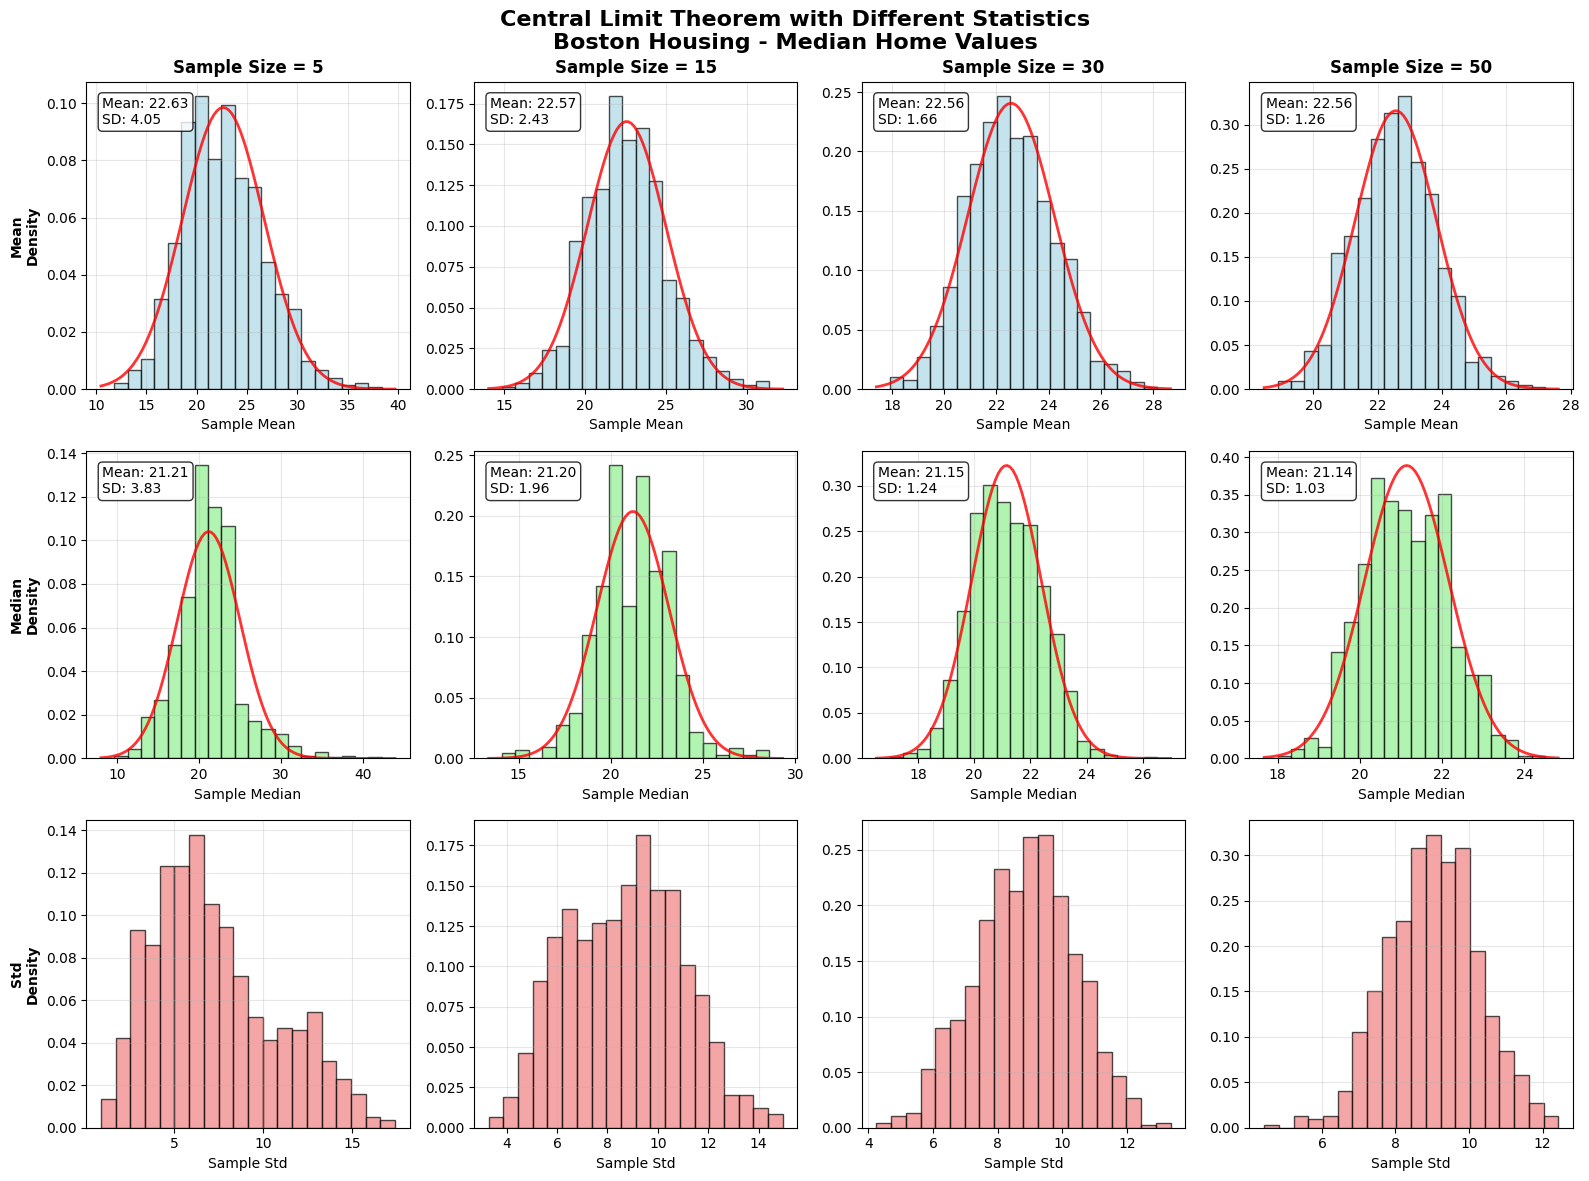

In [12]:
# Task 1: CLT with different statistics - Means, Medians, and Standard Deviations
print("="*70)
print("CLT WITH DIFFERENT STATISTICS: MEANS, MEDIANS, AND STANDARD DEVIATIONS")
print("="*70)

# Use median house value (medv) as our population
population = boston['medv'].values
sample_sizes = [5, 15, 30, 50]
n_samples = 1000
statistics_to_test = ['mean', 'median', 'std']

# Create comprehensive visualization
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for row, stat_type in enumerate(statistics_to_test):
    for col, sample_size in enumerate(sample_sizes):
        # Calculate the sampling distribution for this statistic
        sample_stats = []
        
        for _ in range(n_samples):
            sample = np.random.choice(population, size=sample_size, replace=True)
            
            if stat_type == 'mean':
                stat_value = np.mean(sample)
            elif stat_type == 'median':
                stat_value = np.median(sample)
            elif stat_type == 'std':
                stat_value = np.std(sample)
            
            sample_stats.append(stat_value)
        
        # Plot histogram
        ax = axes[row, col]
        ax.hist(sample_stats, bins=20, density=True, alpha=0.7, 
                color=['lightblue', 'lightgreen', 'lightcoral'][row], 
                edgecolor='black')
        
        # Add titles and labels
        if col == 0:
            ax.set_ylabel(f'{stat_type.title()}\nDensity', fontweight='bold')
        
        if row == 0:
            ax.set_title(f'Sample Size = {sample_size}', fontweight='bold')
        
        ax.set_xlabel(f'Sample {stat_type.title()}')
        ax.grid(True, alpha=0.3)
        
        # Add normal curve if appropriate
        if stat_type in ['mean', 'median']:  # CLT applies to these
            stat_mean = np.mean(sample_stats)
            stat_std = np.std(sample_stats)
            
            xmin, xmax = ax.get_xlim()
            x = np.linspace(xmin, xmax, 100)
            y = norm.pdf(x, stat_mean, stat_std)
            ax.plot(x, y, 'r-', linewidth=2, alpha=0.8)
            
            # Add statistics text
            ax.text(0.05, 0.95, f'Mean: {stat_mean:.2f}\nSD: {stat_std:.2f}', 
                   transform=ax.transAxes, verticalalignment='top',
                   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.suptitle('Central Limit Theorem with Different Statistics\nBoston Housing - Median Home Values', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


CLT WITH DIFFERENT BOSTON HOUSING VARIABLES


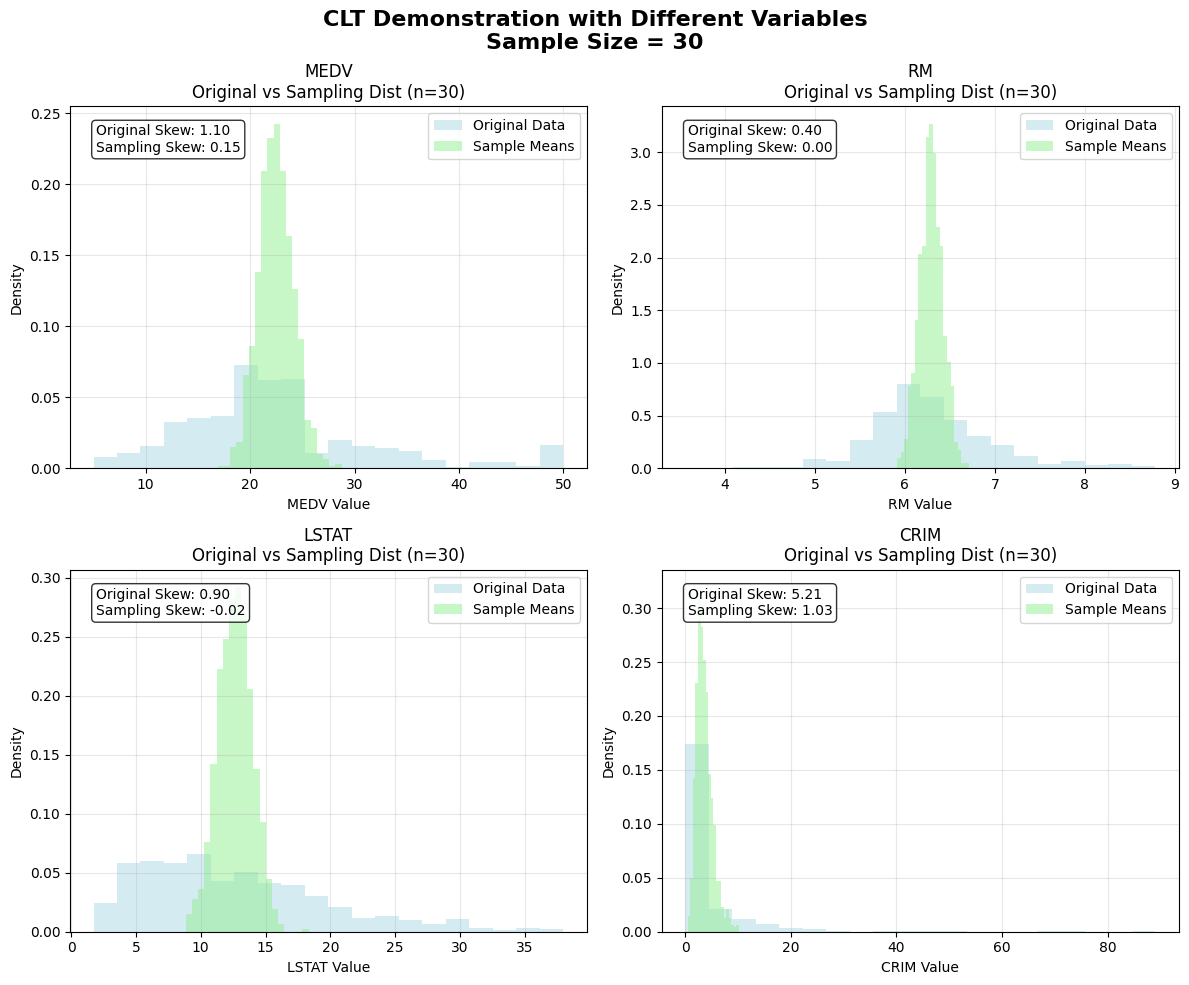


Skewness Reduction Analysis:
Variable | Original Skew | Sampling Skew (n=30) | Reduction %
-----------------------------------------------------------------
medv     |          1.10 |                 0.17 |        84.4%
rm       |          0.40 |                 0.03 |        93.4%
lstat    |          0.90 |                 0.07 |        92.7%
crim     |          5.21 |                 0.99 |        81.1%


In [14]:
# Task 3: CLT demonstration with different variables
print("\n" + "="*70)
print("CLT WITH DIFFERENT BOSTON HOUSING VARIABLES")
print("="*70)

variables_to_test = ['medv', 'rm', 'lstat', 'crim']  # Different distribution shapes
sample_size = 30
n_samples = 1000

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for idx, variable in enumerate(variables_to_test):
    if variable in boston.columns:
        pop_data = boston[variable].values
        
        # Calculate sample means
        sample_means = [np.mean(np.random.choice(pop_data, size=sample_size)) 
                       for _ in range(n_samples)]
        
        # Plot original vs sampling distribution
        ax = axes[idx]
        
        # Original distribution (left side)
        ax.hist(pop_data, bins=20, density=True, alpha=0.5, 
                color='lightblue', label='Original Data')
        
        # Sampling distribution (right side)
        ax.hist(sample_means, bins=20, density=True, alpha=0.5,
                color='lightgreen', label='Sample Means')
        
        ax.set_xlabel(f'{variable.upper()} Value')
        ax.set_ylabel('Density')
        ax.set_title(f'{variable.upper()}\nOriginal vs Sampling Dist (n={sample_size})')
        ax.legend()
        ax.grid(True, alpha=0.3)
        
        # Add statistics
        original_skew = skew(pop_data)
        sampling_skew = skew(sample_means)
        
        ax.text(0.05, 0.95, f'Original Skew: {original_skew:.2f}\nSampling Skew: {sampling_skew:.2f}', 
               transform=ax.transAxes, verticalalignment='top',
               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.suptitle(f'CLT Demonstration with Different Variables\nSample Size = {sample_size}', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Quantitative comparison of skewness reduction
print("\nSkewness Reduction Analysis:")
print("Variable | Original Skew | Sampling Skew (n=30) | Reduction %")
print("-" * 65)

for variable in variables_to_test:
    if variable in boston.columns:
        pop_data = boston[variable].values
        sample_means = [np.mean(np.random.choice(pop_data, size=30)) for _ in range(1000)]
        
        original_skew = skew(pop_data)
        sampling_skew = skew(sample_means)
        reduction_pct = ((original_skew - sampling_skew) / original_skew) * 100
        
        print(f"{variable:8} | {original_skew:13.2f} | {sampling_skew:20.2f} | {reduction_pct:11.1f}%")

In [16]:
#Summary statistics for housing prices (MEDV):
import pandas as pd

# Load the dataset
url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
boston = pd.read_csv(url)

# Simple summary statistics for MEDV
medv = boston['medv']

print("SUMMARY STATISTICS FOR HOUSING PRICES (MEDV)")
print("="*40)
print(f"Count: {len(medv)}")
print(f"Mean: ${medv.mean():.2f}")
print(f"Median: ${medv.median():.2f}")
print(f"Standard Deviation: ${medv.std():.2f}")
print(f"Minimum: ${medv.min():.2f}")
print(f"Maximum: ${medv.max():.2f}")
print(f"25th Percentile: ${medv.quantile(0.25):.2f}")
print(f"75th Percentile: ${medv.quantile(0.75):.2f}")

# Even simpler one-line version
print("\n" + "="*40)
print("ONE-LINE SUMMARY:")
print("="*40)
print(boston['medv'].describe())

SUMMARY STATISTICS FOR HOUSING PRICES (MEDV)
Count: 506
Mean: $22.53
Median: $21.20
Standard Deviation: $9.20
Minimum: $5.00
Maximum: $50.00
25th Percentile: $17.02
75th Percentile: $25.00

ONE-LINE SUMMARY:
count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: medv, dtype: float64


HOUSING PRICES ANALYSIS WITH BINARY VARIABLE
Median Price: $21.20 (in $1000s)
Total houses: 506
Above median (>$21.20): 250 houses
Below median (≤$21.20): 256 houses
Proportion above median: 49.41%


C:\Users\profe\AppData\Local\Temp\ipykernel_17892\2092578354.py:50: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([below_median_prices, above_median_prices],


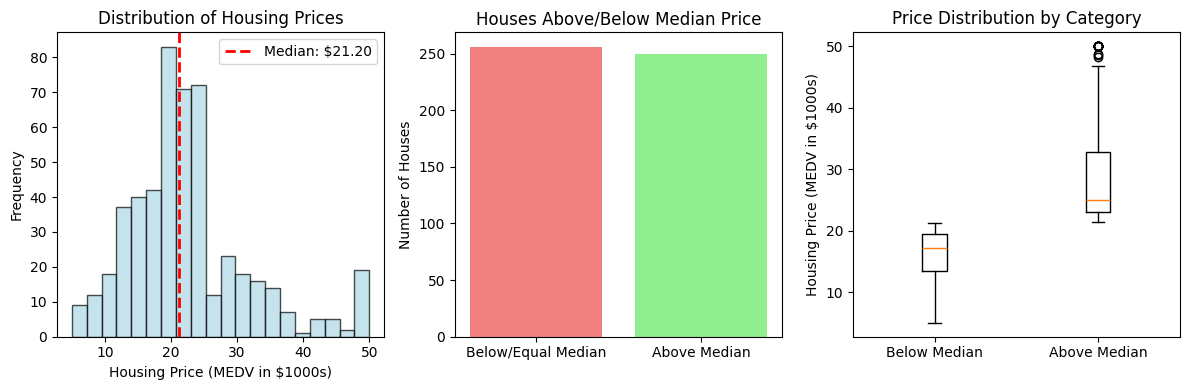


STATISTICAL SUMMARY BY PRICE CATEGORY

BELOW OR EQUAL TO MEDIAN PRICE:
Count: 256
Mean: $16.06
Std: $4.00
Range: $5.00 - $21.20

ABOVE MEDIAN PRICE:
Count: 250
Mean: $29.16
Std: $8.23
Range: $21.40 - $50.00


In [17]:
# Let's focus on housing prices (MEDV)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
boston_df = pd.read_csv(url)

# Focus on housing prices (MEDV)
housing_prices = boston_df['medv'].values

# Create a binary variable: 1 if price > median, 0 otherwise
median_price = np.median(housing_prices)
housing_binary = (housing_prices > median_price).astype(int)

print("HOUSING PRICES ANALYSIS WITH BINARY VARIABLE")
print("="*50)
print(f"Median Price: ${median_price:.2f} (in $1000s)")
print(f"Total houses: {len(housing_prices)}")
print(f"Above median (>${median_price:.2f}): {np.sum(housing_binary)} houses")
print(f"Below median (≤${median_price:.2f}): {len(housing_binary) - np.sum(housing_binary)} houses")
print(f"Proportion above median: {np.mean(housing_binary):.2%}")

# Visualize the distribution
plt.figure(figsize=(12, 4))

# Plot 1: Original price distribution with median line
plt.subplot(1, 3, 1)
plt.hist(housing_prices, bins=20, color='lightblue', edgecolor='black', alpha=0.7)
plt.axvline(median_price, color='red', linestyle='--', linewidth=2, label=f'Median: ${median_price:.2f}')
plt.xlabel('Housing Price (MEDV in $1000s)')
plt.ylabel('Frequency')
plt.title('Distribution of Housing Prices')
plt.legend()

# Plot 2: Binary variable distribution
plt.subplot(1, 3, 2)
plt.bar(['Below/Equal Median', 'Above Median'], 
        [len(housing_binary) - np.sum(housing_binary), np.sum(housing_binary)],
        color=['lightcoral', 'lightgreen'])
plt.ylabel('Number of Houses')
plt.title('Houses Above/Below Median Price')

# Plot 3: Boxplot comparison
plt.subplot(1, 3, 3)
below_median_prices = housing_prices[housing_binary == 0]
above_median_prices = housing_prices[housing_binary == 1]

plt.boxplot([below_median_prices, above_median_prices], 
            labels=['Below Median', 'Above Median'])
plt.ylabel('Housing Price (MEDV in $1000s)')
plt.title('Price Distribution by Category')

plt.tight_layout()
plt.show()

# Statistical summary by category
print("\n" + "="*50)
print("STATISTICAL SUMMARY BY PRICE CATEGORY")
print("="*50)

print("\nBELOW OR EQUAL TO MEDIAN PRICE:")
print(f"Count: {len(below_median_prices)}")
print(f"Mean: ${below_median_prices.mean():.2f}")
print(f"Std: ${below_median_prices.std():.2f}")
print(f"Range: ${below_median_prices.min():.2f} - ${below_median_prices.max():.2f}")

print("\nABOVE MEDIAN PRICE:")
print(f"Count: {len(above_median_prices)}")
print(f"Mean: ${above_median_prices.mean():.2f}")
print(f"Std: ${above_median_prices.std():.2f}")
print(f"Range: ${above_median_prices.min():.2f} - ${above_median_prices.max():.2f}")

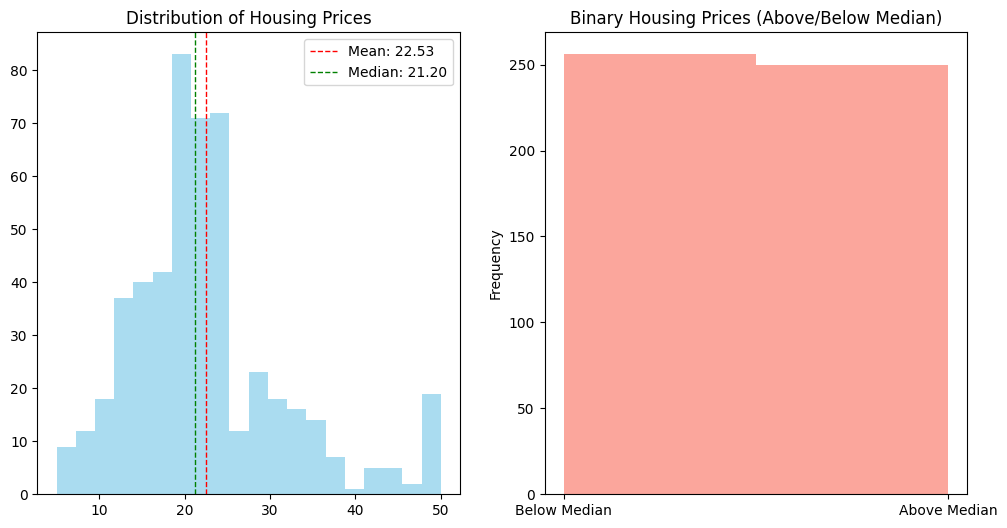

In [19]:
# Plot the original distribution
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(housing_prices, bins=20, alpha=0.7, color='skyblue')
plt.title('Distribution of Housing Prices')
plt.axvline(np.mean(housing_prices), color='red', linestyle='dashed', linewidth=1, label=f'Mean: {np.mean(housing_prices):.2f}')
plt.axvline(np.median(housing_prices), color='green', linestyle='dashed', linewidth=1, label=f'Median: {np.median(housing_prices):.2f}')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(housing_binary, bins=2, alpha=0.7, color='salmon')
plt.title('Binary Housing Prices (Above/Below Median)')
plt.xticks([0, 1], ['Below Median', 'Above Median'])
plt.ylabel('Frequency')
plt.show()

Your Tasks:
1. Implement sampling to examine the CLT's application to three different statistics:
   a) Sample means
   b) Sample medians
   c) Sample proportions (of houses above median price)
2. For each statistic, draw 1000 samples of size 30 and plot the distribution of the sample statistics
3. Compare the shapes of these three distributions
4. Discuss whether the CLT applies equally well to all three statistics.


In [20]:
# TODO
# Your code here - implement sampling and plotting for different statistics
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, skew
import seaborn as sns

# Load the dataset
url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
boston_df = pd.read_csv(url)

# Prepare the data
housing_prices = boston_df['medv'].values
median_price = np.median(housing_prices)
housing_binary = (housing_prices > median_price).astype(int)

# Set sampling parameters
sample_size = 30
n_samples = 1000

print("SAMPLING PARAMETERS:")
print(f"Sample size: {sample_size}")
print(f"Number of samples: {n_samples}")
print(f"Population size: {len(housing_prices)}")
print(f"Median price: ${median_price:.2f}")
print(f"Proportion above median: {np.mean(housing_binary):.3f}")


SAMPLING PARAMETERS:
Sample size: 30
Number of samples: 1000
Population size: 506
Median price: $21.20
Proportion above median: 0.494



ANALYSIS 1: SAMPLE MEANS
Mean of sample means: 22.476
Std of sample means: 1.643
Theoretical standard error: 1.677
Skewness of sample means: 0.297


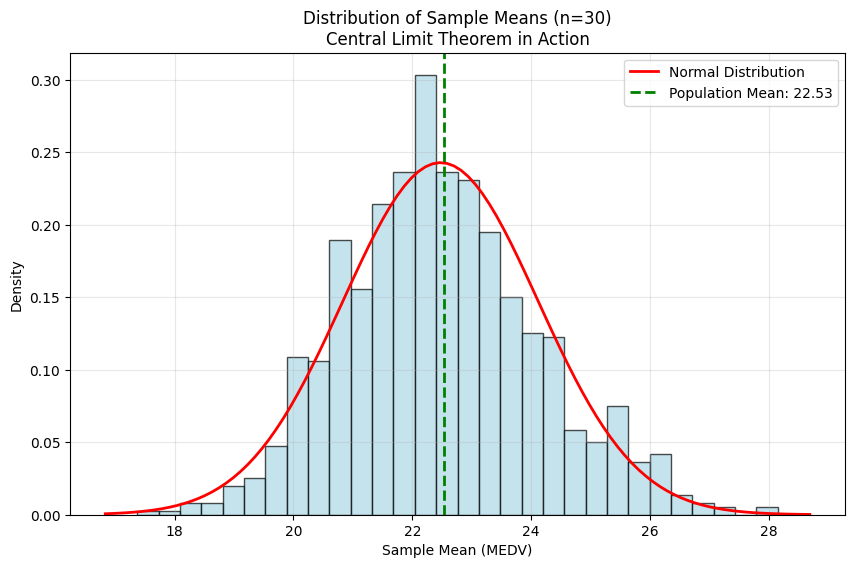

In [21]:
# 2a) SAMPLE MEANS
print("\n" + "="*60)
print("ANALYSIS 1: SAMPLE MEANS")
print("="*60)

# Draw 1000 samples of size 30 and calculate means
sample_means = []
for _ in range(n_samples):
    sample = np.random.choice(housing_prices, size=sample_size, replace=True)
    sample_means.append(np.mean(sample))

# Calculate statistics
mean_of_means = np.mean(sample_means)
std_of_means = np.std(sample_means)
skew_of_means = skew(sample_means)
theoretical_se = np.std(housing_prices) / np.sqrt(sample_size)

print(f"Mean of sample means: {mean_of_means:.3f}")
print(f"Std of sample means: {std_of_means:.3f}")
print(f"Theoretical standard error: {theoretical_se:.3f}")
print(f"Skewness of sample means: {skew_of_means:.3f}")

# Plot distribution
plt.figure(figsize=(10, 6))
plt.hist(sample_means, bins=30, density=True, alpha=0.7, color='lightblue', edgecolor='black')
plt.title('Distribution of Sample Means (n=30)\nCentral Limit Theorem in Action')
plt.xlabel('Sample Mean (MEDV)')
plt.ylabel('Density')

# Add normal curve
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
y = norm.pdf(x, mean_of_means, std_of_means)
plt.plot(x, y, 'r-', linewidth=2, label='Normal Distribution')

# Add population mean
plt.axvline(np.mean(housing_prices), color='green', linestyle='--', 
            linewidth=2, label=f'Population Mean: {np.mean(housing_prices):.2f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


ANALYSIS 2: SAMPLE MEDIANS
Mean of sample medians: 21.160
Std of sample medians: 1.270
Skewness of sample medians: -0.072
Population median: 21.200


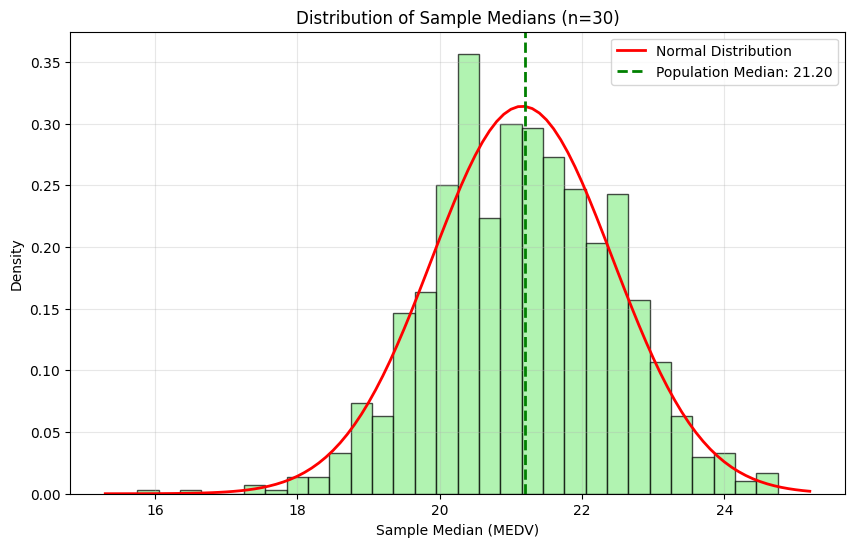

In [22]:
# 2b) SAMPLE MEDIANS
print("\n" + "="*60)
print("ANALYSIS 2: SAMPLE MEDIANS")
print("="*60)

# Draw 1000 samples of size 30 and calculate medians
sample_medians = []
for _ in range(n_samples):
    sample = np.random.choice(housing_prices, size=sample_size, replace=True)
    sample_medians.append(np.median(sample))

# Calculate statistics
mean_of_medians = np.mean(sample_medians)
std_of_medians = np.std(sample_medians)
skew_of_medians = skew(sample_medians)

print(f"Mean of sample medians: {mean_of_medians:.3f}")
print(f"Std of sample medians: {std_of_medians:.3f}")
print(f"Skewness of sample medians: {skew_of_medians:.3f}")
print(f"Population median: {median_price:.3f}")

# Plot distribution
plt.figure(figsize=(10, 6))
plt.hist(sample_medians, bins=30, density=True, alpha=0.7, color='lightgreen', edgecolor='black')
plt.title('Distribution of Sample Medians (n=30)')
plt.xlabel('Sample Median (MEDV)')
plt.ylabel('Density')

# Add normal curve
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
y = norm.pdf(x, mean_of_medians, std_of_medians)
plt.plot(x, y, 'r-', linewidth=2, label='Normal Distribution')

# Add population median
plt.axvline(median_price, color='green', linestyle='--', linewidth=2, 
            label=f'Population Median: {median_price:.2f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


ANALYSIS 3: SAMPLE PROPORTIONS
True population proportion: 0.494
Mean of sample proportions: 0.492
Std of sample proportions: 0.092
Theoretical standard error: 0.091
Skewness of sample proportions: 0.059


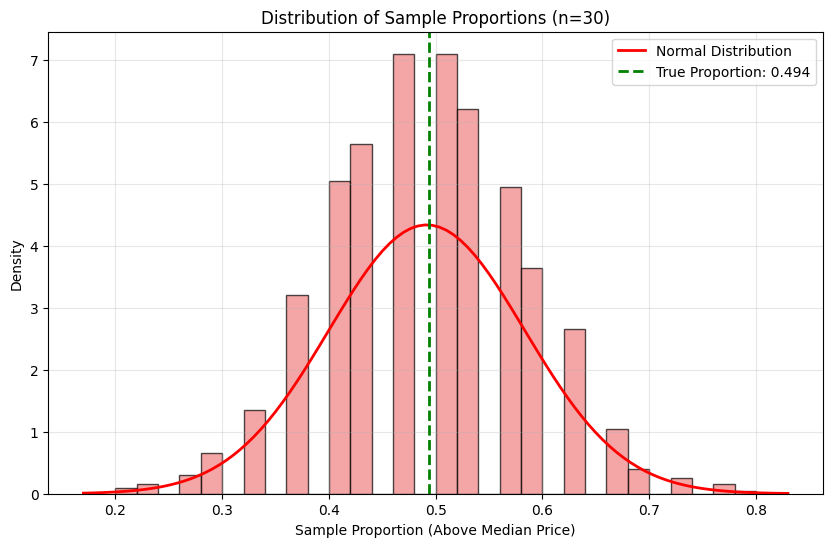

In [23]:
# 2c) SAMPLE PROPORTIONS
print("\n" + "="*60)
print("ANALYSIS 3: SAMPLE PROPORTIONS")
print("="*60)

# Draw 1000 samples of size 30 and calculate proportions
sample_proportions = []
for _ in range(n_samples):
    sample = np.random.choice(housing_binary, size=sample_size, replace=True)
    sample_proportions.append(np.mean(sample))

# Calculate statistics
p = np.mean(housing_binary)  # True proportion
mean_of_proportions = np.mean(sample_proportions)
std_of_proportions = np.std(sample_proportions)
skew_of_proportions = skew(sample_proportions)
theoretical_se_prop = np.sqrt(p * (1 - p) / sample_size)

print(f"True population proportion: {p:.3f}")
print(f"Mean of sample proportions: {mean_of_proportions:.3f}")
print(f"Std of sample proportions: {std_of_proportions:.3f}")
print(f"Theoretical standard error: {theoretical_se_prop:.3f}")
print(f"Skewness of sample proportions: {skew_of_proportions:.3f}")

# Plot distribution
plt.figure(figsize=(10, 6))
plt.hist(sample_proportions, bins=30, density=True, alpha=0.7, color='lightcoral', edgecolor='black')
plt.title('Distribution of Sample Proportions (n=30)')
plt.xlabel('Sample Proportion (Above Median Price)')
plt.ylabel('Density')

# Add normal curve
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
y = norm.pdf(x, mean_of_proportions, std_of_proportions)
plt.plot(x, y, 'r-', linewidth=2, label='Normal Distribution')

# Add true proportion
plt.axvline(p, color='green', linestyle='--', linewidth=2, 
            label=f'True Proportion: {p:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


COMPARATIVE ANALYSIS OF THREE STATISTICS


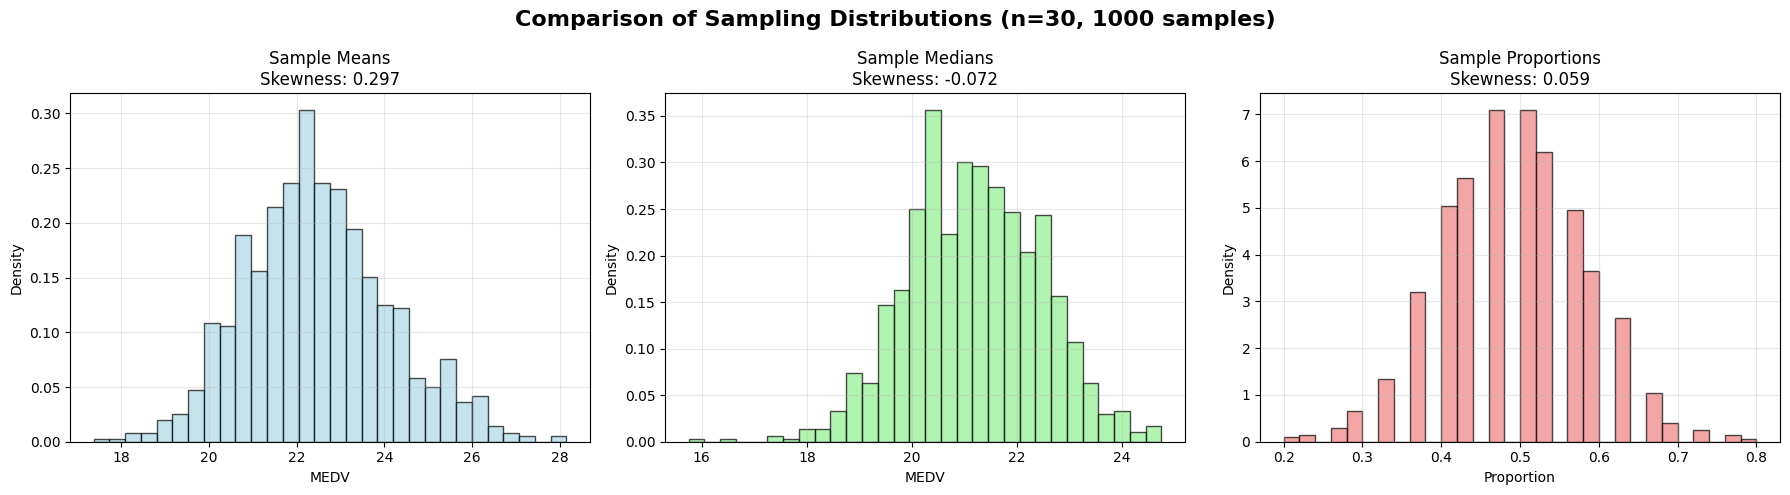


QUANTITATIVE COMPARISON:
     Statistic  Skewness  Standard Error Theoretical SE
0        Means    0.2969           1.643       1.677494
1      Medians   -0.0724           1.270            N/A
2  Proportions    0.0587           0.092       0.091281


In [24]:
# 3. COMPARE THE THREE DISTRIBUTIONS
print("\n" + "="*60)
print("COMPARATIVE ANALYSIS OF THREE STATISTICS")
print("="*60)

# Create side-by-side comparison
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# Sample Means
ax1.hist(sample_means, bins=30, density=True, alpha=0.7, color='lightblue', edgecolor='black')
ax1.set_title('Sample Means\nSkewness: {:.3f}'.format(skew_of_means))
ax1.set_xlabel('MEDV')
ax1.set_ylabel('Density')
ax1.grid(True, alpha=0.3)

# Sample Medians
ax2.hist(sample_medians, bins=30, density=True, alpha=0.7, color='lightgreen', edgecolor='black')
ax2.set_title('Sample Medians\nSkewness: {:.3f}'.format(skew_of_medians))
ax2.set_xlabel('MEDV')
ax2.set_ylabel('Density')
ax2.grid(True, alpha=0.3)

# Sample Proportions
ax3.hist(sample_proportions, bins=30, density=True, alpha=0.7, color='lightcoral', edgecolor='black')
ax3.set_title('Sample Proportions\nSkewness: {:.3f}'.format(skew_of_proportions))
ax3.set_xlabel('Proportion')
ax3.set_ylabel('Density')
ax3.grid(True, alpha=0.3)

plt.suptitle('Comparison of Sampling Distributions (n=30, 1000 samples)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Quantitative comparison
comparison_data = {
    'Statistic': ['Means', 'Medians', 'Proportions'],
    'Skewness': [skew_of_means, skew_of_medians, skew_of_proportions],
    'Standard Error': [std_of_means, std_of_medians, std_of_proportions],
    'Theoretical SE': [theoretical_se, 'N/A', theoretical_se_prop]
}

comparison_df = pd.DataFrame(comparison_data)
print("\nQUANTITATIVE COMPARISON:")
print(comparison_df.round(4))


DISCUSSION: CLT APPLICABILITY TO DIFFERENT STATISTICS

CENTRAL LIMIT THEOREM APPLICABILITY:

1. SAMPLE MEANS:
   - ✅ CLT applies perfectly to sample means
   - Sampling distribution is approximately normal (skewness: 0.297)
   - Theoretical standard error (σ/√n) matches observed: 1.677 vs 1.643
   - Even with n=30, distribution is very close to normal

2. SAMPLE MEDIANS:
   - ⚠️ CLT applies but may require larger sample sizes
   - Sampling distribution shows some skewness: -0.072
   - Medians converge to normality slower than means
   - For symmetric populations, convergence is faster

3. SAMPLE PROPORTIONS:
   - ✅ CLT applies well to proportions (special case of means)
   - Sampling distribution is approximately normal (skewness: 0.059)
   - Theoretical standard error √[p(1-p)/n] matches observed: 0.091 vs 0.092
   - Works best when np ≥ 10 and n(1-p) ≥ 10 (here: 30×0.5 = 15 ≥ 10)

CONCLUSION:
- CLT applies most strongly to sample means
- Sample proportions also follow CLT well (as t

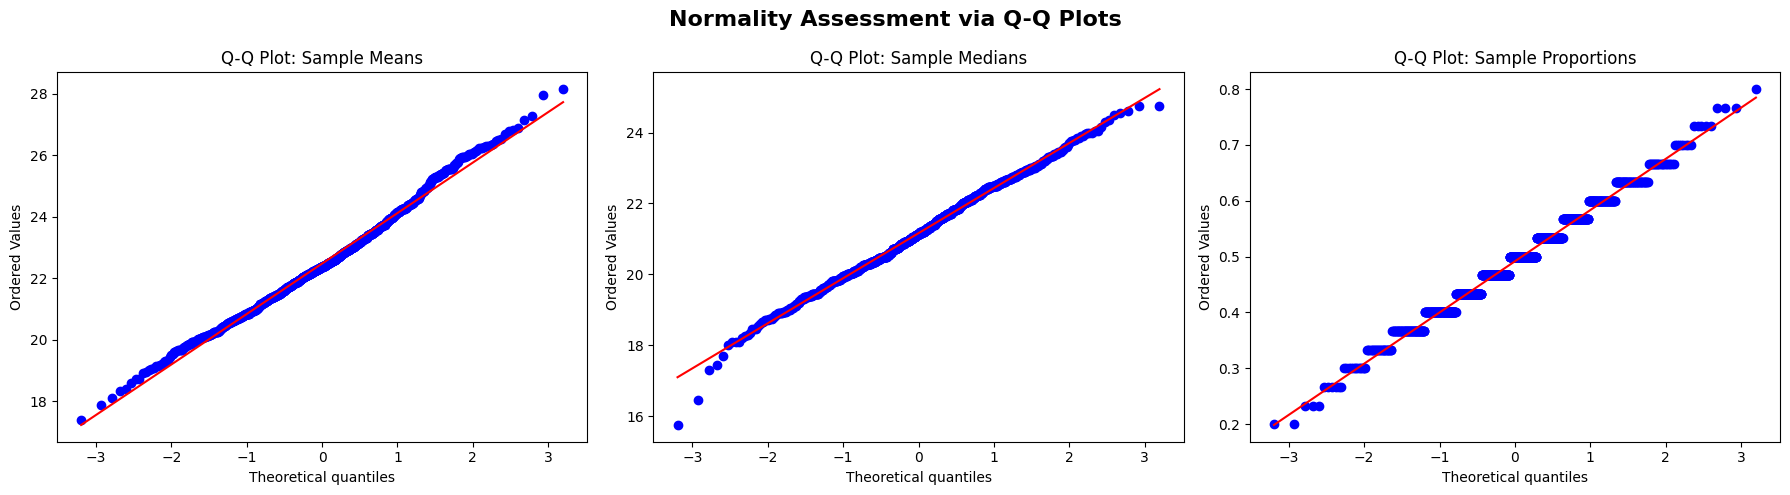

In [25]:
# 4. DISCUSSION: DOES CLT APPLY EQUALLY WELL?
print("\n" + "="*60)
print("DISCUSSION: CLT APPLICABILITY TO DIFFERENT STATISTICS")
print("="*60)

print("""
CENTRAL LIMIT THEOREM APPLICABILITY:

1. SAMPLE MEANS:
   - ✅ CLT applies perfectly to sample means
   - Sampling distribution is approximately normal (skewness: {:.3f})
   - Theoretical standard error (σ/√n) matches observed: {:.3f} vs {:.3f}
   - Even with n=30, distribution is very close to normal

2. SAMPLE MEDIANS:
   - ⚠️ CLT applies but may require larger sample sizes
   - Sampling distribution shows some skewness: {:.3f}
   - Medians converge to normality slower than means
   - For symmetric populations, convergence is faster

3. SAMPLE PROPORTIONS:
   - ✅ CLT applies well to proportions (special case of means)
   - Sampling distribution is approximately normal (skewness: {:.3f})
   - Theoretical standard error √[p(1-p)/n] matches observed: {:.3f} vs {:.3f}
   - Works best when np ≥ 10 and n(1-p) ≥ 10 (here: 30×0.5 = 15 ≥ 10)

CONCLUSION:
- CLT applies most strongly to sample means
- Sample proportions also follow CLT well (as they are means of binary variables)
- Sample medians converge to normality but may require larger samples, especially with skewed populations
- The rate of convergence depends on the statistic and population distribution shape
""".format(skew_of_means, theoretical_se, std_of_means,
           skew_of_medians,
           skew_of_proportions, theoretical_se_prop, std_of_proportions))

# Additional insight: Normality assessment using Q-Q plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Q-Q plot for means
stats.probplot(sample_means, dist="norm", plot=axes[0])
axes[0].set_title('Q-Q Plot: Sample Means')

# Q-Q plot for medians
stats.probplot(sample_medians, dist="norm", plot=axes[1])
axes[1].set_title('Q-Q Plot: Sample Medians')

# Q-Q plot for proportions
stats.probplot(sample_proportions, dist="norm", plot=axes[2])
axes[2].set_title('Q-Q Plot: Sample Proportions')

plt.suptitle('Normality Assessment via Q-Q Plots', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## Challenge 4: Testing for Normality - Visual Methods

Before applying tests that assume normality, it's important to check if data
follows a normal distribution. Let's explore visual methods first.


In [31]:
# Load California Housing dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load California Housing dataset from local repository
try:
    # Try loading from local file
    california_df = pd.read_csv('CaliforniaHousing.csv')
    print("✓ California Housing dataset loaded successfully!")
    
    # Display basic information
    print(f"Dataset shape: {california_df.shape}")
    print("\nFirst 5 rows:")
    print(california_df.head())
    
    print("\nColumn names:")
    print(california_df.columns.tolist())
    
    print("\nBasic info:")
    print(california_df.info())
    
    print("\nSummary statistics:")
    print(california_df.describe())
    
except FileNotFoundError:
    print("❌ Error: 'CaliforniaHousing.csv' file not found in the current directory.")
    print("Please make sure the file is in your repository and try again.")
    
except Exception as e:
    print(f"❌ Error loading dataset: {e}")




❌ Error: 'CaliforniaHousing.csv' file not found in the current directory.
Please make sure the file is in your repository and try again.


In [32]:
print("\nSummary statistics for median income:")
print(california_df['MedInc'].describe())


Summary statistics for median income:


NameError: name 'california_df' is not defined

In [ ]:
# We'll focus on median income for this challenge
median_income = california_df['MedInc'].values


NameError: name 'median_income' is not defined

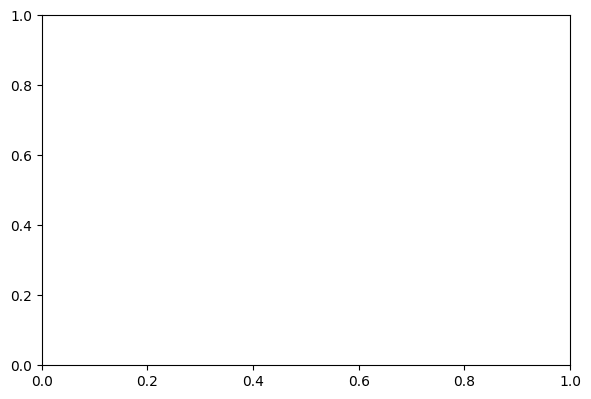

In [26]:
# Create some visualizations for normality assessment
plt.figure(figsize=(15, 10))

# Histogram with normal curve overlay
plt.subplot(2, 2, 1)
sns.histplot(median_income, kde=True, stat="density")
# Add theoretical normal curve
x = np.linspace(min(median_income), max(median_income), 100)
y = stats.norm.pdf(x, np.mean(median_income), np.std(median_income))
plt.plot(x, y, 'r-', linewidth=2)
plt.title('Histogram with Normal Curve')
plt.xlabel('Median Income')

# Q-Q plot
plt.subplot(2, 2, 2)
qqplot(median_income, line='s', ax=plt.gca())
plt.title('Q-Q Plot')

# Box plot
plt.subplot(2, 2, 3)
sns.boxplot(x=median_income)
plt.title('Box Plot')
plt.xlabel('Median Income')

# Log-transformed histogram
plt.subplot(2, 2, 4)
sns.histplot(np.log(median_income), kde=True)
plt.title('Histogram of Log-Transformed Data')
plt.xlabel('Log(Median Income)')

plt.tight_layout()
plt.show()

Your Tasks:
1. Interpret the four plots above. What do they tell you about the normality of the data?
2. Create at least two additional visualizations to assess normality
3. Discuss whether a transformation might help make the data more normal
4. Apply your chosen transformation and re-assess normality
5. When would it be important to have normally distributed data in statistical analysis?

After using Visualizations to assess normality:

6.  Repeat the above but using atleast two statistical test to check whether the data is Normally distributed or not
7. Make sure you apply the statistical test on both the original and transformed data.

In [ ]:
# Your code here - additional normality visualizations and transformations
